# MINI PROJECT 08 : UCI BIKE SHARING END TO END BUSINESS DATA ANALYTICS

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [5]:
# Load Dataset
df = pd.read_csv("Datasets/hour.csv")
print("Dataset Shape :" , df.shape)
df.head()

Dataset Shape : (17379, 17)


,instant,dteday,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,0,6,0,1,0.24,0.2879,0.81,0.0,3,13,16
1,2,2011-01-01,1,0,1,1,0,6,0,1,0.22,0.2727,0.80,0.0,8,32,40
2,3,2011-01-01,1,0,1,2,0,6,0,1,0.22,0.2727,0.80,0.0,5,27,32
3,4,2011-01-01,1,0,1,3,0,6,0,1,0.24,0.2879,0.75,0.0,3,10,13
4,5,2011-01-01,1,0,1,4,0,6,0,1,0.24,0.2879,0.75,0.0,0,1,1


In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 17379 entries, 0 to 17378
Data columns (total 17 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   instant     17379 non-null  int64  
 1   dteday      17379 non-null  object 
 2   season      17379 non-null  int64  
 3   yr          17379 non-null  int64  
 4   mnth        17379 non-null  int64  
 5   hr          17379 non-null  int64  
 6   holiday     17379 non-null  int64  
 7   weekday     17379 non-null  int64  
 8   workingday  17379 non-null  int64  
 9   weathersit  17379 non-null  int64  
 10  temp        17379 non-null  float64
 11  atemp       17379 non-null  float64
 12  hum         17379 non-null  float64
 13  windspeed   17379 non-null  float64
 14  casual      17379 non-null  int64  
 15  registered  17379 non-null  int64  
 16  cnt         17379 non-null  int64  
dtypes: float64(4), int64(12), object(1)
memory usage: 2.3+ MB


In [8]:
df.describe()

,instant,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
count,17379.0000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000
mean,8690.0000,2.501640,0.502561,6.537775,11.546752,0.028770,3.003683,0.682721,1.425283,0.496987,0.475775,0.627229,0.190098,35.676218,153.786869,189.463088
std,5017.0295,1.106918,0.500008,3.438776,6.914405,0.167165,2.005771,0.465431,0.639357,0.192556,0.171850,0.192930,0.122340,49.305030,151.357286,181.387599
min,1.0000,1.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,1.000000,0.020000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000
25%,4345.5000,2.000000,0.000000,4.000000,6.000000,0.000000,1.000000,0.000000,1.000000,0.340000,0.333300,0.480000,0.104500,4.000000,34.000000,40.000000
50%,8690.0000,3.000000,1.000000,7.000000,12.000000,0.000000,3.000000,1.000000,1.000000,0.500000,0.484800,0.630000,0.194000,17.000000,115.000000,142.000000
75%,13034.5000,3.000000,1.000000,10.000000,18.000000,0.000000,5.000000,1.000000,2.000000,0.660000,0.621200,0.780000,0.253700,48.000000,220.000000,281.000000
max,17379.0000,4.000000,1.000000,12.000000,23.000000,1.000000,6.000000,1.000000,4.000000,1.000000,1.000000,1.000000,0.850700,367.000000,886.000000,977.000000


In [10]:
# Check missing values
df.isnull().sum()

instant       0
dteday        0
season        0
yr            0
mnth          0
hr            0
holiday       0
weekday       0
workingday    0
weathersit    0
temp          0
atemp         0
hum           0
windspeed     0
casual        0
registered    0
cnt           0
dtype: int64

In [12]:
# Check duplicate records
print("Duplicate Rows :" , df.duplicated().sum())

Duplicate Rows : 0


In [13]:
# Check date range
print("Starting Date:", df["dteday"].min())
print("Ending Date:", df["dteday"].max())

Starting Date: 2011-01-01
Ending Date: 2012-12-31


In [14]:
# Verify total rentals
print("Rental Count Matches:",
      (df["casual"] + df["registered"] == df["cnt"]).all())

Rental Count Matches: True


In [15]:
# Check whether every record has a unique ID
print("Unique IDs:", df["instant"].is_unique)


Unique IDs: True


## DATA CLEANING AND FEATURE ENGINEERING


In [17]:
# Convert date column to datetime
df["dteday"] = pd.to_datetime(df["dteday"])

# Verify datatype
print("Date Data Type:", df["dteday"].dtype)

# Display first five dates
df[["dteday"]].head()

Date Data Type: datetime64[ns]


,dteday
0,2011-01-01
1,2011-01-01
2,2011-01-01
3,2011-01-01
4,2011-01-01


In [18]:
# Extract date-based features
df["day_name"] = df["dteday"].dt.day_name()

df["month_name"] = df["dteday"].dt.month_name()

df["year_label"] = df["dteday"].dt.year

# Identify weekends
df["is_weekend"] = df["dteday"].dt.dayofweek.isin([5, 6])

# Display new features
df[["dteday", "day_name", "month_name",
    "year_label", "is_weekend"]].head(10)

,dteday,day_name,month_name,year_label,is_weekend
0,2011-01-01,Saturday,January,2011,True
1,2011-01-01,Saturday,January,2011,True
2,2011-01-01,Saturday,January,2011,True
3,2011-01-01,Saturday,January,2011,True
4,2011-01-01,Saturday,January,2011,True
5,2011-01-01,Saturday,January,2011,True
6,2011-01-01,Saturday,January,2011,True
7,2011-01-01,Saturday,January,2011,True
8,2011-01-01,Saturday,January,2011,True
9,2011-01-01,Saturday,January,2011,True


In [19]:
# 1. Create season labels
season_map = {
    1: "Spring",
    2: "Summer",
    3: "Fall",
    4: "Winter"
}

df["season_name"] = df["season"].map(season_map)


# 2. Create weather labels
weather_map = {
    1: "Clear / Partly Cloudy",
    2: "Mist / Cloudy",
    3: "Light Rain / Snow",
    4: "Heavy Rain / Snow"
}

df["weather_label"] = df["weathersit"].map(weather_map)


# 3. Create hourly demand periods
df["hour_period"] = pd.cut(
    df["hr"],
    bins=[-1, 5, 11, 16, 20, 23],
    labels=["Night", "Morning", "Afternoon", "Evening", "Late Night"]
)


# 4. Create working day labels
df["day_type"] = df["workingday"].map({
    0: "Non-Working Day",
    1: "Working Day"
})



print("Updated Dataset Shape:", df.shape)

print("\nMissing Values:")
print(df.isnull().sum().sum())

print("\nDuplicate Rows:", df.duplicated().sum())

print("\nRental Count Validation:",
      (df["casual"] + df["registered"] == df["cnt"]).all())

print("\nNew Feature Preview:")
display(
    df[[
        "dteday",
        "day_name",
        "month_name",
        "year_label",
        "is_weekend",
        "season_name",
        "weather_label",
        "hour_period",
        "day_type"
    ]].head(10)
)

print("\nFinal Column Names:")
print(df.columns.tolist())

Updated Dataset Shape: (17379, 25)

Missing Values:
0

Duplicate Rows: 0

Rental Count Validation: True

New Feature Preview:


,dteday,day_name,month_name,year_label,is_weekend,season_name,weather_label,hour_period,day_type
0,2011-01-01,Saturday,January,2011,True,Spring,Clear / Partly Cloudy,Night,Non-Working Day
1,2011-01-01,Saturday,January,2011,True,Spring,Clear / Partly Cloudy,Night,Non-Working Day
2,2011-01-01,Saturday,January,2011,True,Spring,Clear / Partly Cloudy,Night,Non-Working Day
3,2011-01-01,Saturday,January,2011,True,Spring,Clear / Partly Cloudy,Night,Non-Working Day
4,2011-01-01,Saturday,January,2011,True,Spring,Clear / Partly Cloudy,Night,Non-Working Day
5,2011-01-01,Saturday,January,2011,True,Spring,Mist / Cloudy,Night,Non-Working Day
6,2011-01-01,Saturday,January,2011,True,Spring,Clear / Partly Cloudy,Morning,Non-Working Day
7,2011-01-01,Saturday,January,2011,True,Spring,Clear / Partly Cloudy,Morning,Non-Working Day
8,2011-01-01,Saturday,January,2011,True,Spring,Clear / Partly Cloudy,Morning,Non-Working Day
9,2011-01-01,Saturday,January,2011,True,Spring,Clear / Partly Cloudy,Morning,Non-Working Day



Final Column Names:
['instant', 'dteday', 'season', 'yr', 'mnth', 'hr', 'holiday', 'weekday', 'workingday', 'weathersit', 'temp', 'atemp', 'hum', 'windspeed', 'casual', 'registered', 'cnt', 'day_name', 'month_name', 'year_label', 'is_weekend', 'season_name', 'weather_label', 'hour_period', 'day_type']


## BUSINESS ANALYSIS AND VISUALISATION

1. TOP 5 HOURS BY AVERAGE RENTAL DEMAND


,hr,cnt
17,17,461.452055
18,18,425.510989
8,8,359.011004
16,16,311.983562
19,19,311.523352


2. WEEKDAY RENTAL DEMAND


,day_name,cnt
0,Monday,183.744655
1,Tuesday,191.238891
2,Wednesday,191.130505
3,Thursday,196.436665
4,Friday,196.135907
5,Saturday,190.209793
6,Sunday,177.468825


3. SEASONAL RENTAL DEMAND


,season_name,cnt
0,Spring,111.114569
1,Summer,208.344069
2,Fall,236.016237
3,Winter,198.868856


... (2 outputs left out)

5. CUSTOMER CONTRIBUTION


,Customer Type,Total Rentals,Contribution (%)
0,Casual,620017,18.830168
1,Registered,2672662,81.169832


6. CORRELATION WITH TOTAL RENTALS


,Correlation with Total Rentals
cnt,1.000000
registered,0.972151
casual,0.694564
temp,0.404772
atemp,0.400929
windspeed,0.093234
hum,-0.322911


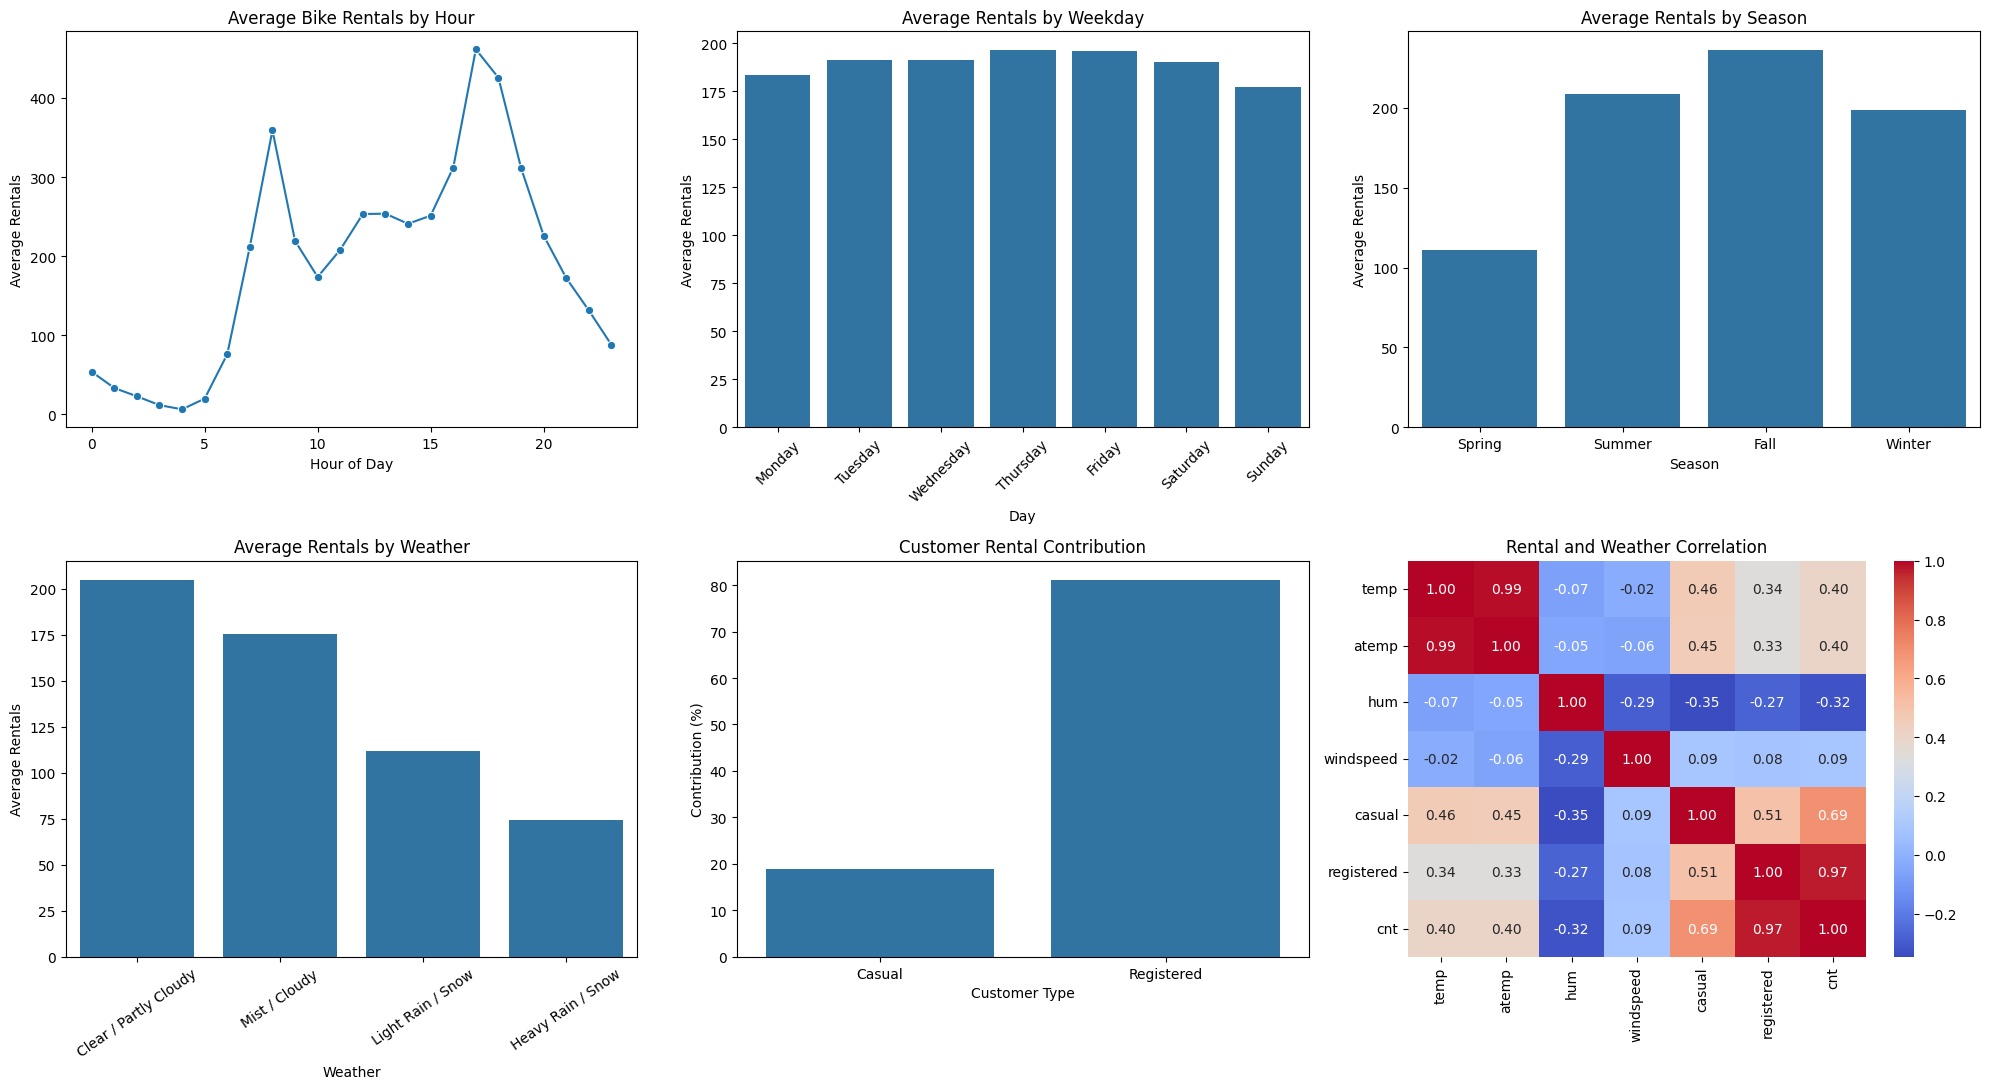

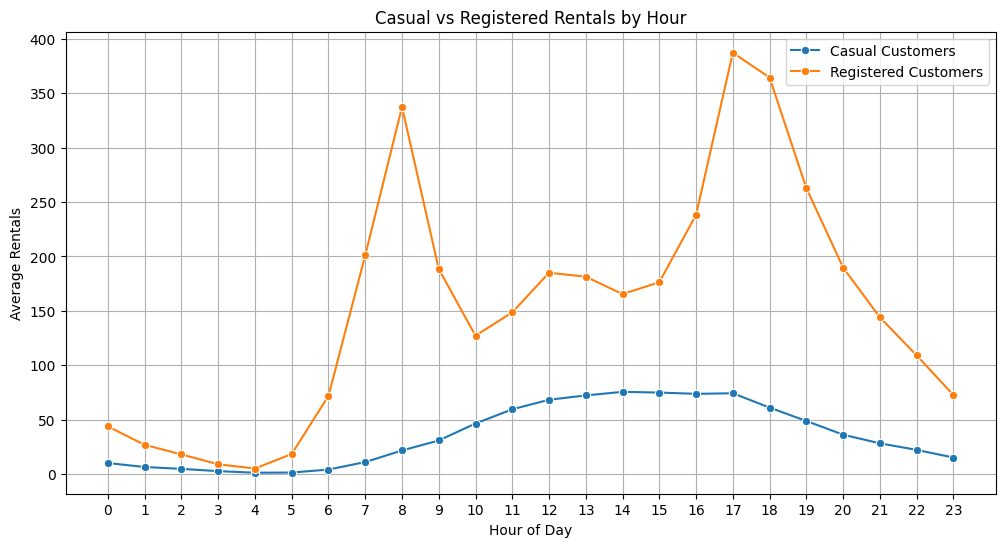

HIGHEST DEMAND HOUR: 17
HIGHEST DEMAND WEEKDAY: Thursday
HIGHEST DEMAND SEASON: Fall
HIGHEST CUSTOMER CONTRIBUTION: Registered


In [20]:
# 1. HOURLY RENTAL DEMAND
hourly_demand = (
    df.groupby("hr")["cnt"]
    .mean()
    .reset_index()
    .sort_values("hr")
)

# 2. WEEKDAY RENTAL DEMAND
weekday_order = [
    "Monday", "Tuesday", "Wednesday",
    "Thursday", "Friday", "Saturday", "Sunday"
]

weekday_demand = (
    df.groupby("day_name")["cnt"]
    .mean()
    .reindex(weekday_order)
    .reset_index()
)

# 3. SEASONAL RENTAL DEMAND
season_order = ["Spring", "Summer", "Fall", "Winter"]

season_demand = (
    df.groupby("season_name")["cnt"]
    .mean()
    .reindex(season_order)
    .reset_index()
)

# 4. WEATHER AND RENTAL DEMAND
weather_demand = (
    df.groupby("weather_label")["cnt"]
    .mean()
    .reset_index()
    .sort_values("cnt", ascending=False)
)

# 5. CUSTOMER TYPE CONTRIBUTION
customer_totals = pd.DataFrame({
    "Customer Type": ["Casual", "Registered"],
    "Total Rentals": [
        df["casual"].sum(),
        df["registered"].sum()
    ]
})

customer_totals["Contribution (%)"] = (
    customer_totals["Total Rentals"]
    / customer_totals["Total Rentals"].sum()
) * 100

# 6. HOURLY CUSTOMER BEHAVIOUR
customer_hourly = (
    df.groupby("hr")[["casual", "registered"]]
    .mean()
    .reset_index()
)

# 7. CORRELATION ANALYSIS
correlation_data = df[
    ["temp", "atemp", "hum", "windspeed",
     "casual", "registered", "cnt"]
]

correlation_matrix = correlation_data.corr()


# ==========================================================
# DISPLAY BUSINESS ANALYSIS TABLES
# ==========================================================

print("1. TOP 5 HOURS BY AVERAGE RENTAL DEMAND")
display(hourly_demand.sort_values(
    "cnt", ascending=False
).head(5))

print("2. WEEKDAY RENTAL DEMAND")
display(weekday_demand)

print("3. SEASONAL RENTAL DEMAND")
display(season_demand)

print("4. WEATHER AND RENTAL DEMAND")
display(weather_demand)

print("5. CUSTOMER CONTRIBUTION")
display(customer_totals)

print("6. CORRELATION WITH TOTAL RENTALS")
display(
    correlation_matrix["cnt"]
    .sort_values(ascending=False)
    .to_frame("Correlation with Total Rentals")
)


# ==========================================================
# VISUALIZATION 1: BUSINESS OVERVIEW DASHBOARD
# ==========================================================

fig, axes = plt.subplots(2, 3, figsize=(20, 11))

# Chart 1: Hourly demand
sns.lineplot(
    data=hourly_demand,
    x="hr",
    y="cnt",
    marker="o",
    ax=axes[0, 0]
)
axes[0, 0].set_title("Average Bike Rentals by Hour")
axes[0, 0].set_xlabel("Hour of Day")
axes[0, 0].set_ylabel("Average Rentals")

# Chart 2: Weekday demand
sns.barplot(
    data=weekday_demand,
    x="day_name",
    y="cnt",
    ax=axes[0, 1]
)
axes[0, 1].set_title("Average Rentals by Weekday")
axes[0, 1].set_xlabel("Day")
axes[0, 1].set_ylabel("Average Rentals")
axes[0, 1].tick_params(axis="x", rotation=45)

# Chart 3: Seasonal demand
sns.barplot(
    data=season_demand,
    x="season_name",
    y="cnt",
    ax=axes[0, 2]
)
axes[0, 2].set_title("Average Rentals by Season")
axes[0, 2].set_xlabel("Season")
axes[0, 2].set_ylabel("Average Rentals")

# Chart 4: Weather demand
sns.barplot(
    data=weather_demand,
    x="weather_label",
    y="cnt",
    ax=axes[1, 0]
)
axes[1, 0].set_title("Average Rentals by Weather")
axes[1, 0].set_xlabel("Weather")
axes[1, 0].set_ylabel("Average Rentals")
axes[1, 0].tick_params(axis="x", rotation=35)

# Chart 5: Customer contribution
sns.barplot(
    data=customer_totals,
    x="Customer Type",
    y="Contribution (%)",
    ax=axes[1, 1]
)
axes[1, 1].set_title("Customer Rental Contribution")
axes[1, 1].set_xlabel("Customer Type")
axes[1, 1].set_ylabel("Contribution (%)")

# Chart 6: Correlation heatmap
sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    ax=axes[1, 2]
)
axes[1, 2].set_title("Rental and Weather Correlation")

plt.tight_layout()
plt.show()


# ==========================================================
# VISUALIZATION 2: CUSTOMER BEHAVIOUR BY HOUR
# ==========================================================

plt.figure(figsize=(12, 6))

sns.lineplot(
    data=customer_hourly,
    x="hr",
    y="casual",
    marker="o",
    label="Casual Customers"
)

sns.lineplot(
    data=customer_hourly,
    x="hr",
    y="registered",
    marker="o",
    label="Registered Customers"
)

plt.title("Casual vs Registered Rentals by Hour")
plt.xlabel("Hour of Day")
plt.ylabel("Average Rentals")
plt.xticks(range(0, 24))
plt.legend()
plt.grid(True)
plt.show()


# ==========================================================
# FINAL BUSINESS SUMMARY
# ==========================================================

print("HIGHEST DEMAND HOUR:",
      int(hourly_demand.loc[
          hourly_demand["cnt"].idxmax(), "hr"
      ]))

print("HIGHEST DEMAND WEEKDAY:",
      weekday_demand.loc[
          weekday_demand["cnt"].idxmax(), "day_name"
      ])

print("HIGHEST DEMAND SEASON:",
      season_demand.loc[
          season_demand["cnt"].idxmax(), "season_name"
      ])

print("HIGHEST CUSTOMER CONTRIBUTION:",
      customer_totals.loc[
          customer_totals["Contribution (%)"].idxmax(),
          "Customer Type"
      ])